# Лабораторная работа № 3
## Предварительная обработка данных
**Цель работы**: познакомиться с теоретическими принципами и инструментальными средствами предварительной обработки данных.

Проанализируем датасет salary. Датасет содержит информацию о рабочих разных профессий и информацию об их работе.

**Признаки**: 
* age – возраст 
* workclass – класс работы 
* fnlwgt –  колонка, которая показывает сколько людей с такими же характеристиками существует
* education – образование 
* education-num – (в задании не указано. скорее всего, кол-во высших образований у человека)
* marital-status – семейное положение 
* occupation – вид деятельности 
* relationship – степень родства 
* race – раса 
* sex – пол 
* capital-gain – прирост капитала 
* capital-loss – убыток капитала 
* hours-per-week – часов в неделю 
* native-country – страна происхождения 
* salary – зарплата

### 0. Импорт необходимых библиотек

In [2]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
%matplotlib inline

### 1. Загрузка датасета salary.csv

In [3]:
data = pd.read_csv('salary.csv', skipinitialspace=True)

### 2. Выведем 5 первых строк

In [3]:
data.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,salary
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


### 3. Базовые методы обнаружения пропущенных значений

#### Метод .info()

* Соотносит максимальное кол-во записей в датафрейме с кол-вом записей в каждом столбце

In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       32561 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education-num   32561 non-null  int64 
 5   marital-status  32561 non-null  object
 6   occupation      32561 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital-gain    32561 non-null  int64 
 11  capital-loss    32561 non-null  int64 
 12  hours-per-week  32561 non-null  int64 
 13  native-country  32561 non-null  object
 14  salary          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB


Всего в датасете 32561 запись. В каждой строке столбца Non-Null также 32561 элементов. Это значит, что пропусков значений в датасете нет

#### Методы .isna() и .sum()

* Последовательное использование .isna() и .sum()

In [5]:
data.isna().sum()

age               0
workclass         0
fnlwgt            0
education         0
education-num     0
marital-status    0
occupation        0
relationship      0
race              0
sex               0
capital-gain      0
capital-loss      0
hours-per-week    0
native-country    0
salary            0
dtype: int64

Использование этих методов также доказывает, что пропуски отсутствуют

* Подсчёт процента пропущенных значений

In [6]:
(data.isna().sum() / len(data)).round(4) * 100

age               0.0
workclass         0.0
fnlwgt            0.0
education         0.0
education-num     0.0
marital-status    0.0
occupation        0.0
relationship      0.0
race              0.0
sex               0.0
capital-gain      0.0
capital-loss      0.0
hours-per-week    0.0
native-country    0.0
salary            0.0
dtype: float64

#### Матрица корреляции пропущенных значений

* Сочетание методов .isnull() и .corr() (матрица корреляции пропущенных значений) позволяет показать, насколько сильно присутствие или отсутствие значений одного признака влияет на присутствие значений другого, если известны пропущенные значения. Однако в данном датасете пропущенные значения отсутствуют

In [7]:
data[['age', 'hours-per-week', 'salary']].isnull().corr()

,age,hours-per-week,salary
age,NaN,NaN,NaN
hours-per-week,NaN,NaN,NaN
salary,NaN,NaN,NaN


### 4. Стратегии работы с пропусками

#### Удаление пропусков

Удаление пропущенных значений позволяет качественно обучить алгоритм, если мы считаем, что пропуски носят полностью случайный характер. Единственным ограничением будет достаточность данных для обучения после удаления пропусков

#### Удаление строк

Наиболее очевидный подход к работе с пропущенными значениями.

В данном датасете отсутствуют пропущенные значения.
Однако удаление выглядело бы так:

In [4]:
data.dropna(axis='index', subset=['sex'], inplace=True)
data['sex'].isna().sum()

np.int64(0)

#### Удаление столбцов

Удаление столбцов можно выполнить с помощью метода .drop()

In [5]:
data.drop(columns=['sex'], inplace=True)
data.columns

Index(['age', 'workclass', 'fnlwgt', 'education', 'education-num',
       'marital-status', 'occupation', 'relationship', 'race', 'capital-gain',
       'capital-loss', 'hours-per-week', 'native-country', 'salary'],
      dtype='object')

#### Заполнение пропусков

Удаление пропусков не всегда возможно. В этом случае используется заполнение через mapping

In [9]:
data = pd.read_csv('salary.csv', skipinitialspace=True)
data = data[['age', 'workclass', 'education', 'race', 'sex']]
map_dict = {'Male' : 0, 'Female' : 1}
data['sex'] = data['sex'].map(map_dict)
data.head()

,age,workclass,education,race,sex
0,39,State-gov,Bachelors,White,0
1,50,Self-emp-not-inc,Bachelors,White,0
2,38,Private,HS-grad,White,0
3,53,Private,11th,Black,0
4,28,Private,Bachelors,Black,1


#### Одномерные методы

Одномерные методы - заполнение с использованием данных одного столбца. Берём данные того же признака

#### Заполнение константой

Самый простой способ работы с пропусками. Например, заполняется нулём. Позволяет не сокращать размер выборки

In [13]:
fillna_const = data.copy()
fillna_const.fillna({'age' : 0}, inplace=True)

In [12]:
data['age'].median(), fillna_const['age'].median()

(37.0, 37.0)

Медианный возраст не изменился, т.к. пропущенных значений не было

#### Заполнение средним арифметическим или медианой

In [14]:
fillna_median = data.copy()
fillna_median['age'] = fillna_median['age'].fillna(fillna_median['age'].median())
fillna_median['age'].isna().sum()

np.int64(0)

У этого метода есть ряд недостатков:
- когда в данных появляется большое кол-во одинаковых близких к среднему значений, мы снижаем ценную вариативность в данных;
- такое заполнение может быть некорректно

#### Заполнение наиболее частотным значением

Для заполнения в категориальных данных подойдёт метод заполнения модой
При большом кол-ве пропусков, можно попробовать создать на их основе новую категорию

In [16]:
data = pd.read_csv('salary.csv')
data_mode = data.copy()
data_mode

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,salary
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32556,27,Private,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,Female,0,0,38,United-States,<=50K
32557,40,Private,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,United-States,>50K
32558,58,Private,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,Female,0,0,40,United-States,<=50K
32559,22,Private,201490,HS-grad,9,Never-married,Adm-clerical,Own-child,White,Male,0,0,20,United-States,<=50K


In [18]:
data_mode.groupby('race')['age'].count()

race
Amer-Indian-Eskimo      311
Asian-Pac-Islander     1039
Black                  3124
Other                   271
White                 27816
Name: age, dtype: int64

In [20]:
mode_value = data_mode['race'].mode()[0]
data_mode['race'] = data_mode['race'].fillna(mode_value)
data_mode.loc[[10, 50]]

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,salary
10,37,Private,280464,Some-college,10,Married-civ-spouse,Exec-managerial,Husband,Black,Male,0,0,80,United-States,>50K
50,25,Private,32275,Some-college,10,Married-civ-spouse,Exec-managerial,Wife,Other,Female,0,0,40,United-States,<=50K


### 5. Кодирование категориальных переменных

In [8]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       32561 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education-num   32561 non-null  int64 
 5   marital-status  32561 non-null  object
 6   occupation      32561 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital-gain    32561 non-null  int64 
 11  capital-loss    32561 non-null  int64 
 12  hours-per-week  32561 non-null  int64 
 13  native-country  32561 non-null  object
 14  salary          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB


* Отдельные категории можно посмотреть с помощью метода .unique()

In [9]:
data['workclass'].unique()

array(['State-gov', 'Self-emp-not-inc', 'Private', 'Federal-gov',
       'Local-gov', '?', 'Self-emp-inc', 'Without-pay', 'Never-worked'],
      dtype=object)

* С помощью методов .value_counts() и np.unique() можно посмотреть и количество объектов в каждой категории

In [10]:
data['workclass'].value_counts()

workclass
Private             22696
Self-emp-not-inc     2541
Local-gov            2093
?                    1836
State-gov            1298
Self-emp-inc         1116
Federal-gov           960
Without-pay            14
Never-worked            7
Name: count, dtype: int64

In [11]:
np.unique(data['workclass'], return_counts=True)

(array(['?', 'Federal-gov', 'Local-gov', 'Never-worked', 'Private',
        'Self-emp-inc', 'Self-emp-not-inc', 'State-gov', 'Without-pay'],
       dtype=object),
 array([ 1836,   960,  2093,     7, 22696,  1116,  2541,  1298,    14]))

* Последовательное применение методов .value_counts() и .count() выведет общее кол-во уникальных категорий

In [12]:
data['workclass'].value_counts().count()

np.int64(9)

* Выведем категории на графике

Text(0, 0.5, 'Кол-во наблюдений в категории')

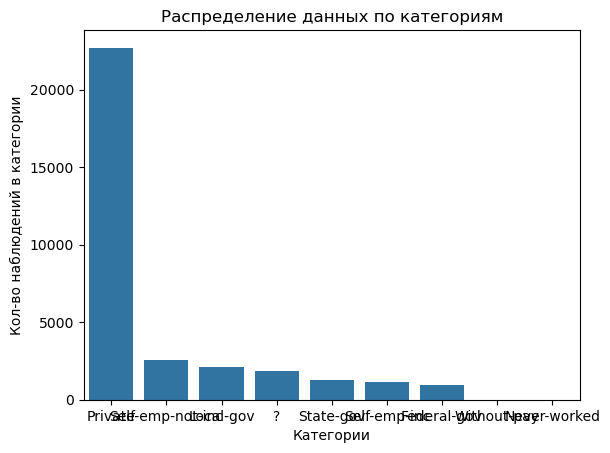

In [13]:
workclass_counts = data['workclass'].value_counts()
sns.barplot(x=workclass_counts.index, y=workclass_counts.values)
plt.title('Распределение данных по категориям')
plt.xlabel('Категории')
plt.ylabel('Кол-во наблюдений в категории')

#### Тип данных category

* Если категорий много, то использование category ускоряет работу с ними и уменьшает использование памяти. Можно воспользоваться методом .astype()

In [14]:
data = data.astype({'sex' : 'category', 'workclass' : 'category'})

* Убедимся, что нужные нам признаки преобразованы в тип category

In [15]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype   
---  ------          --------------  -----   
 0   age             32561 non-null  int64   
 1   workclass       32561 non-null  category
 2   fnlwgt          32561 non-null  int64   
 3   education       32561 non-null  object  
 4   education-num   32561 non-null  int64   
 5   marital-status  32561 non-null  object  
 6   occupation      32561 non-null  object  
 7   relationship    32561 non-null  object  
 8   race            32561 non-null  object  
 9   sex             32561 non-null  category
 10  capital-gain    32561 non-null  int64   
 11  capital-loss    32561 non-null  int64   
 12  hours-per-week  32561 non-null  int64   
 13  native-country  32561 non-null  object  
 14  salary          32561 non-null  object  
dtypes: category(2), int64(6), object(7)
memory usage: 3.3+ MB


#### Базовые методы кодирования

#### Кодирование через cat.codes

In [16]:
data_cat = data.copy()
data_cat['workclass'].cat.codes

0        7
1        6
2        4
3        4
4        4
        ..
32556    4
32557    4
32558    4
32559    4
32560    5
Length: 32561, dtype: int8

In [17]:
data_cat['workclass'] = data_cat['workclass'].astype('category').cat.codes
data_cat

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,salary
0,39,7,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,6,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,4,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,4,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,4,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32556,27,4,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,Female,0,0,38,United-States,<=50K
32557,40,4,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,United-States,>50K
32558,58,4,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,Female,0,0,40,United-States,<=50K
32559,22,4,201490,HS-grad,9,Never-married,Adm-clerical,Own-child,White,Male,0,0,20,United-States,<=50K


#### Mapping

* Суть способа заключается в том, чтобы передать схему кодирования в виде словаря в функцию map() и применить к соответствующему столбцу

In [18]:
data_map = data.copy()
map_dict = {
    'Male' : 0,
    'Female' : 1
}
data_map['sex'] = data_map['sex'].map(map_dict)
data_map

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,salary
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,0,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,0,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,0,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,0,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,1,0,0,40,Cuba,<=50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32556,27,Private,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,1,0,0,38,United-States,<=50K
32557,40,Private,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,0,0,0,40,United-States,>50K
32558,58,Private,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,1,0,0,40,United-States,<=50K
32559,22,Private,201490,HS-grad,9,Never-married,Adm-clerical,Own-child,White,0,0,0,20,United-States,<=50K


#### OneHotEncoding

* Категории, в которых больше двух классов, но нет внутренней иерархии, называются номинальными данными. Их нельзя заменять числами, т.к. построенная на основе преобразованных данных модель может подумать, что между категориями есть иерархия, когда в действительности её нет. В таких случаях нужно использовать OneHotEncoding

In [19]:
data_enc = data.copy()
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
encoded_arr = encoder.fit_transform(data_enc[['workclass']])
data_encoded = pd.DataFrame(encoded_arr, columns=encoder.get_feature_names_out(['workclass']))
data_encoded.head()

,workclass_?,workclass_Federal-gov,workclass_Local-gov,workclass_Never-worked,workclass_Private,workclass_Self-emp-inc,workclass_Self-emp-not-inc,workclass_State-gov,workclass_Without-pay
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0


* Присоединение новых признаков к исходному датафрейму, удалив признак 'workclass'

In [20]:
data_onehot = data_enc.join(data_encoded)
data_onehot.drop('workclass', axis=1, inplace=True)
data_onehot.head()

,age,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,...,salary,workclass_?,workclass_Federal-gov,workclass_Local-gov,workclass_Never-worked,workclass_Private,workclass_Self-emp-inc,workclass_Self-emp-not-inc,workclass_State-gov,workclass_Without-pay
0,39,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,...,<=50K,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,50,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,...,<=50K,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,38,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,...,<=50K,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
3,53,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,...,<=50K,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
4,28,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,...,<=50K,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0


* Можно убрать один из новых признаков, т.к. при срабатывании этого признака, остальные признаки будут иметь значение 0 

In [21]:
data_onehot.drop(columns='workclass_?', inplace=True)
data_onehot.head()

,age,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,...,native-country,salary,workclass_Federal-gov,workclass_Local-gov,workclass_Never-worked,workclass_Private,workclass_Self-emp-inc,workclass_Self-emp-not-inc,workclass_State-gov,workclass_Without-pay
0,39,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,...,United-States,<=50K,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,50,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,...,United-States,<=50K,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,38,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,...,United-States,<=50K,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
3,53,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,...,United-States,<=50K,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
4,28,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,...,Cuba,<=50K,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
